/Users/evandaniels/Research/runs/whistler_conv/N200: Nx = 200, 1001 outputs
/Users/evandaniels/Research/runs/whistler_conv/N400: Nx = 400, 1001 outputs
/Users/evandaniels/Research/runs/whistler_conv/N800: Nx = 800, 1001 outputs

whistler (R)
  m  k di  w theory |   err N=200   err N=400   err N=800 |  order  order |  g/w N=200  g/w N=400  g/w N=800
  1  0.50    1.2808 |   -4.10e-05   -1.14e-05   -1.43e-06 |   1.84   3.00 |    7.3e-04    7.8e-05    8.6e-06
  2  1.00    3.2361 |   -2.12e-04   -4.40e-05   -7.97e-06 |   2.27   2.47 |    9.3e-04    1.2e-04    1.2e-05
  3  1.50    6.0000 |   -7.59e-04   -1.66e-04   -3.88e-05 |   2.19   2.10 |    9.4e-04    1.4e-04    1.5e-05
  4  2.00    9.6569 |   -1.77e-03   -4.01e-04   -9.55e-05 |   2.15   2.07 |    9.8e-04    1.7e-04    1.8e-05
  5  2.50   14.2539 |   -3.05e-03   -7.34e-04   -1.74e-04 |   2.05   2.08 |    1.0e-03    1.8e-04    1.8e-05
  6  3.00   19.8167 |   -4.82e-03   -1.16e-03   -2.69e-04 |   2.05   2.11 |    1.1e-03    1.8e-04    2.2

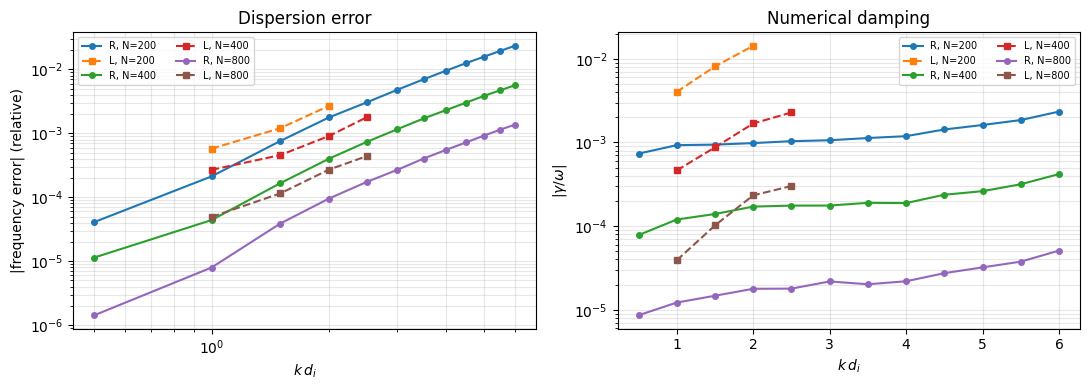

In [6]:
"""
whistler_convergence.py -- convergence of the Hall-MHD dispersion test (problem = 2)

For each run (same box, different Nx) and each excited mode k_m = m*2pi/Lx, the complex
Fourier amplitudes c(t) = FFT_x[By + i Bz] at +k and -k are fitted with the matrix-pencil
method: a sum of damped complex exponentials  sum_j A_j exp(-(i w_j + g_j) t).
This gives each branch's frequency w and damping rate g far more precisely than a peak
in an FFT spectrum (no window or bin bias), which is what a convergence study needs.

Theory (vA = 1):  whistler  w_R = k (sqrt(1+(k di/2)^2) + k di/2)
                  ion-cyc.  w_L = k (sqrt(1+(k di/2)^2) - k di/2)
                  damping   g = 0   (eta = 0: any damping is numerical dissipation)

Output: per mode and branch, the frequency error at each resolution, the observed order
between successive resolutions, and the numerical damping g/w.
"""
import os, glob
import numpy as np
import matplotlib.pyplot as plt

BASE = os.path.expanduser('~/Research/runs/whistler_conv')
RUNS = {200: 'N200', 400: 'N400', 800: 'N800'}
DI, P, DT_OUT, T_FINAL, M_MODES = 0.5, 10, 0.02, 20.0, 12
N_POLES = 4          # at most this many exponentials per series (physical: R and L)
MIN_AMP = 1e-3       # a pole counts if |A| > MIN_AMP * largest |A| for that k
GAP = 10.0           # signal/noise split: first drop of > GAP x between singular values


def omega_theory(k):
    s = np.sqrt(1 + (k*DI/2)**2)
    return k*(s + k*DI/2), k*(s - k*DI/2)


def load(run, name, n):
    return np.vstack([np.loadtxt(f'{run}/{name}_files/{name}_p{p:03d}_{n:03d}', ndmin=2)
                      for p in range(P)])


def matrix_pencil(y, dt, M):
    """Fit y[n] = sum_j A_j z_j^n. Returns omega, gamma, amplitude per pole (y ~ exp(-(i w + g) t))."""
    N = len(y); L = N // 2
    Y = np.array([y[i:i + L + 1] for i in range(N - L)])
    _, S, Vh = np.linalg.svd(Y, full_matrices=False)
    # keep only the components above the noise floor: cut at the first big gap in the
    # singular values (fitting noise components makes the amplitudes, and hence the
    # choice of pole, unreliable)
    r = S[:M] / S[1:M + 1]
    big = np.where(r > GAP)[0]
    M = int(big[0]) + 1 if big.size else M
    V = Vh[:M].T                              # rows of Vh span {z^j}; no conjugate
    z = np.linalg.eigvals(np.linalg.pinv(V[:-1]) @ V[1:])
    Z = z[None, :] ** np.arange(N)[:, None]
    A = np.linalg.lstsq(Z, y, rcond=None)[0]
    lz = np.log(z) / dt                       # = -(i w + g)
    return -lz.imag, -lz.real, A


def analyse(run):
    x = np.concatenate([np.loadtxt(f'{run}/mesh_files/x_p{p:03d}', ndmin=1) for p in range(P)])
    Nx, Lx = len(x), (x[1] - x[0])*len(x)
    nmax = len(glob.glob(f'{run}/b2_files/b2_p000_*'))
    ns = [n for n in range(nmax) if n*DT_OUT <= T_FINAL + 1e-9]
    b = np.array([load(run, 'b2', n).mean(axis=1) + 1j*load(run, 'b3', n).mean(axis=1) for n in ns])
    Bk = np.fft.fft(b, axis=1) / Nx
    out = {}
    for m in range(1, M_MODES + 1):
        wR, wL = omega_theory(m*2*np.pi/Lx)
        poles = []
        for idx in (m, Nx - m):               # +k and -k
            w, g, A = matrix_pencil(Bk[:, idx], DT_OUT, N_POLES)
            poles += list(zip(np.abs(w), g, np.abs(A)))
        amax = max(p[2] for p in poles)
        good = [p for p in poles if p[2] > MIN_AMP*amax]
        res = {}
        for name, wt in (('R', wR), ('L', wL)):
            cand = [p for p in good if abs(p[0] - wt) < 0.25*wt]
            if name == 'L' and wL*1.25 > wR*0.75:   # branches overlap: L not separable
                cand = []
            if cand:
                p = max(cand, key=lambda q: q[2])          # strongest pole in the window
                res[name] = dict(w=p[0], g=p[1], th=wt, err=(p[0] - wt)/wt)
        out[m] = res
    print(f'{run}: Nx = {Nx}, {len(ns)} outputs')
    return out


res = {N: analyse(os.path.join(BASE, f)) for N, f in sorted(RUNS.items())
       if os.path.isdir(os.path.join(BASE, f))}
Ns = sorted(res)


def row(branch):
    print(f"\n{'whistler (R)' if branch == 'R' else 'ion cyclotron (L)'}")
    hdr = f"{'m':>3} {'k di':>5} {'w theory':>9} | " + ' '.join(f'{"err N="+str(N):>11}' for N in Ns)
    hdr += ' | ' + ' '.join(f'{"order":>6}' for _ in Ns[1:]) + ' | ' + ' '.join(f'{"g/w N="+str(N):>10}' for N in Ns)
    print(hdr)
    for m in range(1, M_MODES + 1):
        e = [res[N][m].get(branch) for N in Ns]
        if all(v is None for v in e):
            continue
        k = m*2*np.pi/(2*np.pi)          # Lx = 2pi in this test
        th = next(v['th'] for v in e if v)
        s = f'{m:>3} {k*DI:>5.2f} {th:>9.4f} | '
        s += ' '.join(f'{v["err"]:>11.2e}' if v else f'{"n/d":>11}' for v in e)
        s += ' | '
        orders = []
        for a, b in zip(e[:-1], e[1:]):
            orders.append(f'{np.log2(abs(a["err"])/abs(b["err"])):>6.2f}' if a and b and b['err'] != 0 else f'{"":>6}')
        s += ' '.join(orders) + ' | '
        s += ' '.join(f'{v["g"]/v["w"]:>10.1e}' if v else f'{"n/d":>10}' for v in e)
        print(s)


row('R'); row('L')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for N in Ns:
    for br, mk in (('R', 'o-'), ('L', 's--')):
        ks = [m*DI for m in range(1, M_MODES + 1) if br in res[N][m]]
        es = [abs(res[N][m][br]['err']) for m in range(1, M_MODES + 1) if br in res[N][m]]
        a1.loglog(ks, es, mk, ms=4, label=f'{br}, N={N}')
        gs = [res[N][m][br]['g']/res[N][m][br]['w'] for m in range(1, M_MODES + 1) if br in res[N][m]]
        a2.semilogy(ks, np.abs(gs), mk, ms=4, label=f'{br}, N={N}')
a1.set(xlabel=r'$k\,d_i$', ylabel='|frequency error| (relative)', title='Dispersion error')
a2.set(xlabel=r'$k\,d_i$', ylabel=r'$|\gamma/\omega|$', title='Numerical damping')
for a in (a1, a2):
    a.grid(alpha=0.3, which='both'); a.legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(os.path.join(BASE, 'whistler_convergence.png'), dpi=150); plt.show()